Clase 013 · `013_numpy` · La segunda libreta de la clase está escrita como guion, con su
explicación entre celdas. Multiplicación de matrices a mano y con `@`, cuatro formas de recorrer
un DataFrame de cien mil renglones, y el decorador `@njit` de Numba para compilar un ciclo que
no se puede quitar. Todo con datos generados en la libreta: no lee archivos externos. `numba`
se instala con `uv add numba`.

Idea central de la libreta:

> **Un ciclo `for` en Python puro es lento. NumPy y Numba hacen el mismo trabajo en código compilado, mucho más rápido.**

| Parte | Tema |
|---|---|
| 1 | Multiplicación de matrices: a mano y con NumPy |
| 2 | Recorrer un DataFrame: con ciclos y sin ciclos |
| 3 | Numba: acelerar un ciclo `for` con una sola línea |

Los tiempos cambian de una computadora a otra. Lo que importa es **cuántas veces** un método es más rápido que otro.

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

## Cómo vamos a medir el tiempo

Siempre con el mismo patrón de tres líneas: anotar la hora de inicio, hacer el trabajo, restar.

```python
inicio = time.perf_counter()
...  # el trabajo
tiempo = time.perf_counter() - inicio      # segundos
```

## Parte 1 · Multiplicación de matrices

### 1.1 La definición

Si $A$ tiene $m$ renglones y $n$ columnas, y $B$ tiene $n$ renglones y $p$ columnas, el producto $C = AB$
tiene $m$ renglones y $p$ columnas. Cada elemento se calcula así:

$$
C_{ij} = \sum_{k} A_{ik}\, B_{kj}
$$

En palabras: **tomo el renglón $i$ de $A$ y la columna $j$ de $B$, multiplico pareja por pareja y sumo.**

Regla de dimensiones: las **columnas de $A$** deben ser iguales a los **renglones de $B$**.

### 1.2 A mano, con listas

Dos matrices pequeñas como listas de listas:

In [2]:
A = [[1, 2, 3],
     [4, 5, 6]]          # 2 renglones x 3 columnas

B = [[7,  8],
     [9,  10],
     [11, 12]]           # 3 renglones x 2 columnas

El resultado tendrá 2 renglones y 2 columnas. Para llenarlo necesitamos **tres ciclos**:
uno por renglón de $A$, uno por columna de $B$ y uno para ir sumando.

In [3]:
C = [[0, 0],
     [0, 0]]             # resultado vacío, 2 x 2

for i in range(2):              # renglón i de A
    for j in range(2):          # columna j de B
        suma = 0
        for k in range(3):      # recorro la pareja A[i][k] * B[k][j]
            suma = suma + A[i][k] * B[k][j]
        C[i][j] = suma

C

[[58, 64], [139, 154]]

Comprobemos un elemento a mano. El de la esquina superior izquierda es renglón 0 de $A$ por columna 0 de $B$:

$1\cdot7 + 2\cdot9 + 3\cdot11 = 7 + 18 + 33 = 58$ ✔

### 1.3 Con NumPy: el operador `@`

Convertimos las listas a arreglos y usamos `@`. Ya no escribimos ningún ciclo.

In [4]:
A = np.array(A)
B = np.array(B)

A @ B

array([[ 58,  64],
       [139, 154]])

Mismo resultado que con los tres ciclos.

**Cuidado:** en NumPy el asterisco `*` **no** es multiplicación de matrices, es multiplicación elemento por elemento.
Con `A` y `B` ni siquiera funciona, porque no tienen la misma forma:

In [5]:
A * B

ValueError: operands could not be broadcast together with shapes (2,3) (3,2) 

Con dos matrices del mismo tamaño sí funciona, pero da otra cosa:

In [6]:
M = np.array([[1, 2],
              [3, 4]])

print("M * M  (elemento por elemento)")
print(M * M)
print()
print("M @ M  (producto de matrices)")
print(M @ M)

M * M  (elemento por elemento)
[[ 1  4]
 [ 9 16]]

M @ M  (producto de matrices)
[[ 7 10]
 [15 22]]


### 1.4 Las dimensiones

Escribe las formas una junto a otra: los dos números de en medio deben ser iguales y "desaparecen":

$$(2 \times \underline{3}) \cdot (\underline{3} \times 2) \;\to\; (2 \times 2)$$

In [7]:
print("A:", A.shape)
print("B:", B.shape)
print("A @ B:", (A @ B).shape)

A: (2, 3)
B: (3, 2)
A @ B: (2, 2)


`B @ A` sí se puede: `(3, 2)` por `(2, 3)` da `(3, 3)`. Otro tamaño, otro resultado.

In [8]:
# B @ A también se puede: (3 x 2) por (2 x 3) da (3 x 3)
B @ A

array([[ 39,  54,  69],
       [ 49,  68,  87],
       [ 59,  82, 105]])

`A @ A` no: `(2, 3)` por `(2, 3)`, los números de en medio no coinciden y el error lo dice con
la firma de `matmul`.

In [9]:
# A @ A no se puede: (2 x 3) por (2 x 3), el 3 y el 2 de en medio no coinciden
A @ A

ValueError: matmul: Input operand 1 has a mismatch in its core dimension 0, with gufunc signature (n?,k),(k,m?)->(n?,m?) (size 2 is different from 3)

### 1.5 Dos propiedades para recordar

- **No es conmutativa**: $AB$ y $BA$ en general son diferentes (arriba ya vimos que ni siquiera tienen el mismo tamaño).
- **La identidad no cambia nada**: $A I = A$. La identidad se crea con `np.eye`.

In [10]:
I = np.eye(3)       # identidad 3 x 3 (unos en la diagonal, ceros en el resto)
print(I)
print()
print(A @ I)

[[1. 0. 0.]
 [0. 1. 0.]
 [0. 0. 1.]]

[[1. 2. 3.]
 [4. 5. 6.]]


### 1.6 Un ejemplo útil: rotar puntos

Una matriz de rotación por un ángulo $\theta$ es

$$
R = \begin{pmatrix} \cos\theta & -\sin\theta \\ \sin\theta & \cos\theta \end{pmatrix}
$$

Si pongo las coordenadas de varios puntos en una matriz (un renglón de $x$, otro de $y$),
**`R @ puntos` rota todos los puntos de un solo golpe.**

In [11]:
angulo = np.deg2rad(30)           # 30 grados en radianes

R = np.array([[np.cos(angulo), -np.sin(angulo)],
              [np.sin(angulo),  np.cos(angulo)]])

# Esquinas de un cuadrado (la última repite la primera para cerrar la figura)
puntos = np.array([[0, 2, 2, 0, 0],      # x
                   [0, 0, 2, 2, 0]])     # y

rotados = R @ puntos
rotados.round(2)

array([[ 0.  ,  1.73,  0.73, -1.  ,  0.  ],
       [ 0.  ,  1.  ,  2.73,  1.73,  0.  ]])

Los dos cuadrados dibujados con `plt.plot`: `puntos[0]` son las `x` y `puntos[1]` las `y`.
`axis("equal")` evita que la rotación se vea deformada.

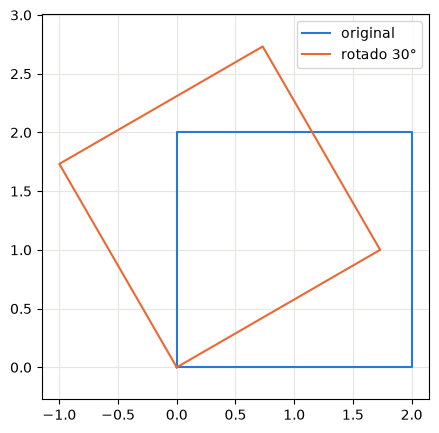

In [12]:
#| label: fig-numpy-rotacion
#| fig-cap: "Un cuadrado de lado 2 (azul) y el mismo cuadrado rotado 30 grados con `R @ puntos` (naranja). Una multiplicación de matrices rota todos los vértices de un golpe."
#| fig-alt: "Dos cuadrados con un vértice común en el origen; el naranja está girado 30 grados en sentido antihorario respecto al azul."
plt.figure(figsize=(5, 5))
plt.plot(puntos[0], puntos[1], color="#2a78d6", label="original")
plt.plot(rotados[0], rotados[1], color="#eb6834", label="rotado 30°")
plt.axis("equal")
plt.grid(True, color="#e6e5e2")
plt.legend()
plt.show()

### 1.7 ¿Cuánto más rápido es NumPy?

Para dos matrices de $200 \times 200$ hay que hacer $200^3 = 8$ millones de multiplicaciones.
Primero con los tres ciclos en Python, luego con `@`.

In [13]:
n = 200
rng = np.random.default_rng(0)
X = rng.random((n, n))
Y = rng.random((n, n))

Los tres ciclos en Python, cronometrados: casi cuatro segundos para 200 por 200.

In [14]:
inicio = time.perf_counter()

Z = np.zeros((n, n))
for i in range(n):
    for j in range(n):
        suma = 0.0
        for k in range(n):
            suma = suma + X[i, k] * Y[k, j]
        Z[i, j] = suma

tiempo_ciclos = time.perf_counter() - inicio
print("tres ciclos en Python:", round(tiempo_ciclos, 3), "segundos")

tres ciclos en Python: 3.924 segundos


`@` es tan rápido que una sola ejecución no se alcanza a medir bien (además la primera vez NumPy tarda un poco en "despertar").
Por eso lo repetimos 100 veces y dividimos entre 100.

In [15]:
inicio = time.perf_counter()

for repeticion in range(100):
    Z2 = X @ Y

tiempo_arroba = (time.perf_counter() - inicio) / 100
print("NumPy con @:", round(tiempo_arroba, 5), "segundos")

NumPy con @: 0.00097 segundos


Comparamos los dos resultados y calculamos cuántas veces es más rápido `@`. En la máquina de
la clase, unas cuatro mil.

In [16]:
print("¿Dan lo mismo?", np.allclose(Z, Z2))
print("NumPy es", round(tiempo_ciclos / tiempo_arroba), "veces más rápido")

¿Dan lo mismo? True
NumPy es 4030 veces más rápido


> Usamos `np.allclose` y no `==` porque las sumas de decimales se hacen en distinto orden y pueden diferir en el último dígito.

### 1.8 Ejercicios

1. Calcula `A @ B` con lápiz y papel y compáralo con la celda de NumPy.
2. Crea una matriz de $3 \times 4$ y otra de $4 \times 1$. ¿Qué forma tiene su producto?
3. Rota el cuadrado 90° y luego 180°. ¿Qué pasa si haces `R @ R @ puntos` con `R` de 90°?

## Parte 2 · Recorrer un DataFrame: con ciclos y sin ciclos

### 2.1 Los datos

Mediciones de una estación solar: hora del día, irradiancia $G$ (W/m²) y temperatura $T$ (°C).
Son datos inventados, pero con la forma de un día real.

In [17]:
N = 100_000
rng = np.random.default_rng(42)

hora = rng.uniform(0, 24, N)
irradiancia = 1000 * np.exp(-((hora - 13) / 3) ** 2) + rng.normal(0, 40, N)
irradiancia = np.clip(irradiancia, 0, None)                 # no hay irradiancia negativa
temperatura = 18 + 10 * np.exp(-((hora - 15) / 4) ** 2) + rng.normal(0, 1.5, N)

df = pd.DataFrame({"hora": hora.round(2),
                   "irradiancia": irradiancia.round(1),
                   "temperatura": temperatura.round(1)})
df.head()

,hora,irradiancia,temperatura
0,18.57,74.2,20.7
1,10.53,456.3,20.7
2,20.61,23.9,17.1
3,16.74,212.3,26.8
4,2.26,94.7,17.4


### 2.2 El cálculo

Queremos la potencia que entrega un panel fotovoltaico en cada renglón:

$$
P = G \cdot \text{área} \cdot \eta \cdot \big(1 - 0.004\,(T + 0.03\,G - 25)\big)
$$

Vamos a calcular **lo mismo cuatro veces**, cada vez de una forma distinta, y a medir cuánto tarda cada una.

In [18]:
AREA = 1.6      # m²
ETA = 0.20      # eficiencia del panel (20 %)

#### Forma 1 · `iterrows`: un ciclo renglón por renglón

`iterrows` entrega cada renglón como una `Series` de pandas. Es la forma más natural de leer... y una de las más lentas.

In [19]:
inicio = time.perf_counter()

potencia = []
for indice, fila in df.iterrows():
    g = fila["irradiancia"]
    t = fila["temperatura"]
    p = g * AREA * ETA * (1 - 0.004 * (t + 0.03 * g - 25))
    potencia.append(p)

tiempo_iterrows = time.perf_counter() - inicio
df["potencia_1"] = potencia
print("iterrows:", round(tiempo_iterrows, 3), "segundos")

iterrows: 2.287 segundos


#### Forma 2 · `itertuples`: el mismo ciclo, renglones más ligeros

`itertuples` entrega cada renglón como una tupla con nombres. Es mucho más barato de crear que una `Series`.

In [20]:
inicio = time.perf_counter()

potencia = []
for fila in df.itertuples():
    g = fila.irradiancia
    t = fila.temperatura
    p = g * AREA * ETA * (1 - 0.004 * (t + 0.03 * g - 25))
    potencia.append(p)

tiempo_itertuples = time.perf_counter() - inicio
df["potencia_2"] = potencia
print("itertuples:", round(tiempo_itertuples, 3), "segundos")

itertuples: 0.118 segundos


#### Forma 3 · Columnas completas de pandas (sin ciclo)

Aquí está el cambio de mentalidad: **no recorremos renglones.** Escribimos la fórmula con las columnas enteras
y pandas hace el ciclo por dentro, en código compilado.

Fíjate que la fórmula es **exactamente la misma**; solo cambia que `g` y `t` ahora son columnas y no números.

In [21]:
inicio = time.perf_counter()

g = df["irradiancia"]
t = df["temperatura"]
df["potencia_3"] = g * AREA * ETA * (1 - 0.004 * (t + 0.03 * g - 25))

tiempo_pandas = time.perf_counter() - inicio
print("columnas de pandas:", round(tiempo_pandas, 5), "segundos")

columnas de pandas: 0.00218 segundos


#### Forma 4 · Arreglos de NumPy (sin ciclo)

Una columna de pandas carga un índice y verificaciones extra en cada operación.
Con `.to_numpy()` sacamos el arreglo "pelón" y operamos directamente con NumPy.

In [22]:
inicio = time.perf_counter()

g = df["irradiancia"].to_numpy()
t = df["temperatura"].to_numpy()
df["potencia_4"] = g * AREA * ETA * (1 - 0.004 * (t + 0.03 * g - 25))

tiempo_numpy = time.perf_counter() - inicio
print("arreglos de NumPy:", round(tiempo_numpy, 5), "segundos")

arreglos de NumPy: 0.0011 segundos


### 2.3 Comparación

Primero verificamos que las cuatro columnas son iguales:

In [23]:
print(np.allclose(df["potencia_1"], df["potencia_4"]))
print(np.allclose(df["potencia_2"], df["potencia_4"]))
print(np.allclose(df["potencia_3"], df["potencia_4"]))

True
True
True


La tabla resume los cuatro tiempos y los normaliza contra el más rápido. Con `iterrows` el
mismo cálculo tarda unas dos mil veces más que con NumPy.

In [24]:
tiempos = pd.Series({"iterrows": tiempo_iterrows,
                     "itertuples": tiempo_itertuples,
                     "columnas pandas": tiempo_pandas,
                     "arreglos NumPy": tiempo_numpy})

tabla = pd.DataFrame({"segundos": tiempos.round(5),
                      "veces más lento que NumPy": (tiempos / tiempo_numpy).round(0)})
tabla

,segundos,veces más lento que NumPy
iterrows,2.28679,2081.0
itertuples,0.11797,107.0
columnas pandas,0.00218,2.0
arreglos NumPy,0.00110,1.0


La misma tabla como barras en escala logarítmica: sin ella, las tres barras rápidas no se verían.

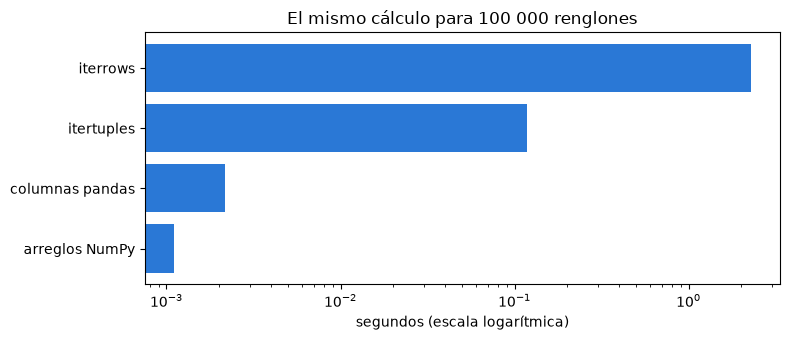

In [25]:
#| label: fig-numpy-tiempos-iteracion
#| fig-cap: "Tiempo del mismo cálculo sobre 100 000 renglones con `iterrows`, `itertuples`, columnas de pandas y arreglos de NumPy, en escala logarítmica. De `iterrows` a NumPy hay tres órdenes de magnitud."
#| fig-alt: "Cuatro barras horizontales azules; la de iterrows llega a dos segundos y la de arreglos NumPy a una milésima."
plt.figure(figsize=(8, 3.5))
plt.barh(tiempos.index, tiempos.values, color="#2a78d6")
plt.xscale("log")
plt.xlabel("segundos (escala logarítmica)")
plt.title("El mismo cálculo para 100 000 renglones")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

### 2.4 ¿Y si hay un `if`?

La objeción típica: *"mi cálculo tiene una condición, necesito un ciclo"*. Casi nunca es cierto: `np.where` hace el `if`
sobre toda la columna de una vez.

Marquemos cada renglón como `"dia"` si la irradiancia es mayor que 5 W/m², y `"noche"` si no.

In [26]:
# Con ciclo
inicio = time.perf_counter()

etiqueta = []
for fila in df.itertuples():
    if fila.irradiancia > 5:
        etiqueta.append("dia")
    else:
        etiqueta.append("noche")

tiempo_if_ciclo = time.perf_counter() - inicio
print("if dentro de un ciclo:", round(tiempo_if_ciclo, 4), "segundos")

if dentro de un ciclo: 0.1048 segundos


La versión sin ciclo: `np.where(condición, valor_si_cierto, valor_si_falso)` sobre la columna completa.

In [27]:
# Sin ciclo: np.where(condición, valor_si_cierto, valor_si_falso)
inicio = time.perf_counter()

df["momento"] = np.where(df["irradiancia"] > 5, "dia", "noche")

tiempo_if_numpy = time.perf_counter() - inicio
print("np.where:", round(tiempo_if_numpy, 4), "segundos")
print("np.where es", round(tiempo_if_ciclo / tiempo_if_numpy), "veces más rápido")

np.where: 0.0097 segundos
np.where es 11 veces más rápido


`value_counts` confirma que la etiqueta quedó puesta: 71 500 renglones de día y 28 500 de noche.

In [28]:
df["momento"].value_counts()

momento
dia      71500
noche    28500
Name: count, dtype: int64

### 2.5 Reglas de oro

1. **Primero intenta sin ciclo.** Escribe la fórmula con las columnas completas.
2. Un `if` se vuelve `np.where`.
3. Si de verdad necesitas recorrer renglones, usa `itertuples`, nunca `iterrows`.
4. Para cálculos pesados, saca los arreglos con `.to_numpy()`.
5. Si el ciclo no se puede quitar (por ejemplo, cada paso depende del anterior): **Numba**, en la siguiente parte.

## Parte 3 · Numba: acelerar un ciclo `for` con una línea

### 3.1 ¿Qué es?

Numba es un **compilador**. Toma una función de Python con ciclos y números, y la primera vez que la llamas la traduce
a código máquina. De ahí en adelante corre a velocidad de C.

Para usarlo hay que poner el decorador `@njit` encima de una función. **Esta es la única parte de la libreta donde
necesitamos escribir funciones**, porque Numba compila funciones, no celdas sueltas.

```python
from numba import njit

@njit
def nombre(argumentos):
    ...
```

Numba entiende números, arreglos de NumPy, ciclos e `if`. **No** entiende DataFrames ni listas de cosas raras.

In [29]:
from numba import njit

### 3.2 Ejemplo: sumar una serie

Vamos a sumar $\displaystyle 1 + \frac{1}{4} + \frac{1}{9} + \frac{1}{16} + \cdots = \sum_{k=1}^{n} \frac{1}{k^2}$
con $n$ = 10 millones. Este número se acerca a $\pi^2 / 6 \approx 1.6449$.

**Primero en Python puro**, como lo hemos hecho siempre:

In [30]:
n = 10_000_000

inicio = time.perf_counter()

total = 0.0
for k in range(1, n + 1):
    total = total + 1.0 / (k * k)

tiempo_python = time.perf_counter() - inicio
print("resultado:", total)
print("Python puro:", round(tiempo_python, 3), "segundos")

resultado: 1.6449339668472596
Python puro: 1.997 segundos


**Ahora con Numba.** Metemos el mismo ciclo dentro de una función y le ponemos `@njit`. El código de adentro **no cambia**.

In [31]:
@njit
def suma_serie(n):
    total = 0.0
    for k in range(1, n + 1):
        total = total + 1.0 / (k * k)
    return total

La **primera llamada** incluye el tiempo de compilar. Las siguientes ya no.

In [32]:
inicio = time.perf_counter()
resultado = suma_serie(n)
tiempo_primera = time.perf_counter() - inicio
print("Numba, primera llamada (compila + calcula):", round(tiempo_primera, 3), "segundos")

Numba, primera llamada (compila + calcula): 0.252 segundos


La segunda llamada ya está compilada: milésimas de segundo, mismo resultado.

In [33]:
inicio = time.perf_counter()
resultado = suma_serie(n)
tiempo_numba = time.perf_counter() - inicio
print("resultado:", resultado)
print("Numba, segunda llamada:", round(tiempo_numba, 4), "segundos")

resultado: 1.6449339668472596
Numba, segunda llamada: 0.0059 segundos


La aceleración, como dato: unas 340 veces.

In [34]:
print("Numba es", round(tiempo_python / tiempo_numba), "veces más rápido que Python puro")

Numba es 340 veces más rápido que Python puro


### 3.3 El triple ciclo de la Parte 1, compilado

En la Parte 1 los tres ciclos tardaron casi un segundo para $200 \times 200$. Mismos ciclos, con `@njit`:

In [35]:
@njit
def multiplica(X, Y):
    n = X.shape[0]
    Z = np.zeros((n, n))
    for i in range(n):
        for j in range(n):
            suma = 0.0
            for k in range(n):
                suma = suma + X[i, k] * Y[k, j]
            Z[i, j] = suma
    return Z

La primera llamada compila y no se mide; la segunda sí. Los tres tiempos juntos: los ciclos en
Python, los mismos ciclos compilados y `@`.

In [36]:
Z3 = multiplica(X, Y)          # primera llamada: compila, no la medimos

inicio = time.perf_counter()
Z3 = multiplica(X, Y)
tiempo_numba_mat = time.perf_counter() - inicio

print("¿Da lo mismo que X @ Y?", np.allclose(Z3, X @ Y))
print()
print("tres ciclos en Python:", round(tiempo_ciclos, 3), "segundos")
print("tres ciclos con Numba:", round(tiempo_numba_mat, 4), "segundos")
print("NumPy con @:          ", round(tiempo_arroba, 5), "segundos")

¿Da lo mismo que X @ Y? True

tres ciclos en Python: 3.924 segundos
tres ciclos con Numba: 0.0036 segundos
NumPy con @:           0.00097 segundos


Dos lecciones:

- El **mismo ciclo** pasa de segundos a milésimas de segundo solo por compilarlo.
- `@` sigue siendo el más rápido: NumPy usa bibliotecas optimizadas durante décadas.
  **Si NumPy ya tiene la operación, úsala. Numba es para los ciclos que NumPy no puede quitar.**

### 3.4 Resumen

| Situación | Qué usar |
|---|---|
| La operación ya existe en NumPy o pandas (`@`, `sum`, `np.where`...) | esa operación, sin ciclo |
| Fórmula renglón por renglón | columnas completas o `.to_numpy()` |
| Un ciclo que no se puede quitar | una función con `@njit` |
| Tengo que recorrer renglones de un DataFrame sí o sí | `itertuples` |

### 3.5 Ejercicios

1. Cambia `n` a 100 millones en `suma_serie`. ¿Cuánto tarda Numba? ¿Te atreves a probarlo en Python puro?
2. Escribe con `@njit` una función que reciba un arreglo y cuente cuántos valores son mayores que 300. Compárala con `(arreglo > 300).sum()` de NumPy.
3. Llama `suma_serie(10.0)` con un decimal en lugar de un entero. Mide la primera y la segunda llamada: ¿por qué la primera vuelve a ser lenta?